# Fase 4 · MODEL — Construcción y selección del modelo

**Objetivo:** entrenar y comparar algoritmos de clasificación supervisada que reconozcan patrones
asociados con vulnerabilidades, seleccionar el mejor con un criterio justificado y serializar el
modelo junto con su pipeline.

El modelo tiene tres componentes aprendidos:

1. **Detector** (binario): ¿la unidad es vulnerable?
2. **Categorizador** (multietiqueta): ¿qué categorías OWASP Top 10:2025 y API Security Top 10:2023?
3. **Clasificador de CWE** (multiclase): ¿qué debilidad concreta? (descripción y recomendación)

La búsqueda completa de hiperparámetros la ejecuta `scripts/entrenar.py`, que guarda los resultados en
`resultados/`. En este notebook se muestran esos resultados y se **reentrena** cada algoritmo con su mejor
configuración para reproducir la comparación.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE))
sys.path.insert(0, str(BASE / "notebooks"))
sys.path.insert(0, str(BASE / "scripts"))
import estilo as E  # noqa: E402
from vulnminer.modelo import NOMBRES_ALGORITMO, REJILLAS, ModeloVulnminer, a_unidades, crear_clasificador, representacion  # noqa: E402

E.aplicar()
df = pd.read_csv(BASE / "datos" / "dataset.csv", keep_default_na=False)
tr, va = df[df.particion == "entrenamiento"], df[df.particion == "validacion"]
comp = pd.read_csv(BASE / "resultados" / "comparacion_detector.csv")
comp_cat = pd.read_csv(BASE / "resultados" / "comparacion_categorias.csv")
metricas = json.loads((BASE / "resultados" / "metricas.json").read_text())

## 1. Algoritmos e hiperparámetros

| Algoritmo | Por qué se incluye | Hiperparámetros explorados |
|---|---|---|
| **Regresión logística** | Lineal, rápida sobre matrices dispersas de alta dimensión, probabilidades bien calibradas y coeficientes interpretables | `C` (inverso de la regularización L2) |
| **SVM lineal** (calibrada) | Margen máximo; muy usada en clasificación de texto | `C`; calibración sigmoide con 3 pliegues estratificados |
| **Random Forest** | No lineal, capta interacciones entre variables | número de variables seleccionadas por χ² (`k`), `min_samples_leaf`; 400 árboles |
| **Gradient Boosting** (HistGradientBoosting) | Ensamble por *boosting*, fuerte en datos tabulares | `learning_rate`, `max_leaf_nodes`; 300 iteraciones sobre 200 componentes SVD |

Todos usan pesos de clase balanceados. Además se probaron dos pesos para el bloque de características de
seguridad (1 y 3) frente a los bloques TF-IDF. Los hiperparámetros se eligen en **validación**; la
partición de **prueba** no participa en ninguna decisión.

In [2]:
pd.DataFrame([{"algoritmo": NOMBRES_ALGORITMO[a], "configuraciones": len(r), "rejilla": "; ".join(json.dumps(p) for p in r)}
              for a, r in REJILLAS.items()])

,algoritmo,configuraciones,rejilla
0,Regresión logística,4,"{""C"": 2.0}; {""C"": 8.0}; {""C"": 32.0}; {""C"": 128.0}"
1,SVM lineal (calibrada),3,"{""C"": 0.2}; {""C"": 1.0}; {""C"": 4.0}"
2,Random Forest,4,"{""k"": 3000, ""n_estimators"": 400, ""min_samples_..."
3,Gradient Boosting (HistGB + SVD),4,"{""componentes"": 200, ""learning_rate"": 0.05, ""m..."


## 2. Variante de la representación (conjunto de desarrollo)

La partición de validación proviene de las mismas fuentes que el entrenamiento, por lo que favorece
variables que separan *fuentes* más que *vulnerabilidades* (por ejemplo, el estilo: el código de
producción tiene más condicionales y manejo de excepciones que las pruebas de reglas). Para elegir la
representación usé un **conjunto de desarrollo a nivel de proyecto**: vulnerabilidades documentadas de
aplicaciones reales (laboratorios de PyGoat y NodeGoat) frente a todas las unidades de cinco proyectos
benignos reservados (tres implementaciones de RealWorld en FastAPI, Spring Boot y NestJS, y los
microservicios Robot Shop y FTGO). Ninguno participa en el entrenamiento ni en la evaluación final.

Las variantes cambian solo el bloque de características de seguridad: indicadores como log(1 + conteo) o
como presencia (0/1), y con o sin las métricas de estilo del código.

In [3]:
var = pd.read_csv(BASE / "resultados" / "seleccion_variante.csv")
var[["variante", "peso_seguridad", "val_ap", "dev_ap", "dev_auc", "dev_sensibilidad_5pct"]].round(3).rename(columns={
    "variante": "Variante", "peso_seguridad": "Peso", "val_ap": "AP validación", "dev_ap": "AP desarrollo",
    "dev_auc": "AUC desarrollo", "dev_sensibilidad_5pct": "Sensibilidad con 5 % de falsas alarmas"})

,Variante,Peso,AP validación,AP desarrollo,AUC desarrollo,Sensibilidad con 5 % de falsas alarmas
0,log sin estilo,1.0,0.713,0.591,0.961,0.806
1,binario sin estilo,1.0,0.735,0.552,0.951,0.722
2,log + estilo,1.0,0.722,0.508,0.935,0.722
3,binario + estilo,1.0,0.746,0.455,0.928,0.694
4,log sin estilo,3.0,0.717,0.414,0.926,0.694
5,binario sin estilo,3.0,0.732,0.401,0.927,0.722
6,binario + estilo,3.0,0.745,0.338,0.906,0.694
7,log + estilo,3.0,0.725,0.294,0.899,0.667


In [4]:
print("Variante seleccionada:", metricas["representacion"]["variante"])

Variante seleccionada: log sin estilo


## 3. Comparación experimental del detector (validación)

Criterio de selección: **precisión promedio (AP)**, el área bajo la curva precisión–sensibilidad. No
depende del umbral y es adecuada con clases desbalanceadas. Se informan también F1, precisión,
sensibilidad y AUC-ROC. Dentro de cada algoritmo aplico una **regla de parsimonia**: entre las
configuraciones cuya AP está a menos de 0,01 de la mejor, elijo la más regularizada (menor `C`), porque
generaliza mejor a proyectos nuevos y evita que variables poco frecuentes reciban pesos excesivos.

In [5]:
cols = ["nombre", "peso_seguridad", "hiperparametros", "val_ap", "val_roc_auc", "val_precision", "val_recall", "val_f1",
        "val_f1_umbral", "segundos"]
comp[cols].sort_values("val_ap", ascending=False).round(3).reset_index(drop=True)

,nombre,peso_seguridad,hiperparametros,val_ap,val_roc_auc,val_precision,val_recall,val_f1,val_f1_umbral,segundos
0,SVM lineal (calibrada),1.0,"{""C"": 4.0}",0.740,0.849,0.701,0.704,0.702,0.716,9.4
1,Regresión logística,1.0,"{""C"": 32.0}",0.736,0.847,0.670,0.765,0.714,0.721,6.8
2,SVM lineal (calibrada),3.0,"{""C"": 4.0}",0.735,0.845,0.699,0.707,0.703,0.713,67.0
3,SVM lineal (calibrada),1.0,"{""C"": 1.0}",0.735,0.847,0.686,0.705,0.695,0.704,3.7
4,Regresión logística,3.0,"{""C"": 32.0}",0.735,0.843,0.677,0.758,0.715,0.718,27.7
5,Regresión logística,1.0,"{""C"": 128.0}",0.734,0.844,0.676,0.768,0.719,0.721,13.0
6,Regresión logística,3.0,"{""C"": 128.0}",0.733,0.840,0.673,0.761,0.714,0.720,33.1
7,SVM lineal (calibrada),3.0,"{""C"": 1.0}",0.731,0.845,0.689,0.702,0.696,0.708,24.6
8,Regresión logística,1.0,"{""C"": 8.0}",0.731,0.845,0.653,0.770,0.707,0.709,4.9
9,Regresión logística,3.0,"{""C"": 8.0}",0.730,0.843,0.650,0.763,0.702,0.710,16.5


In [6]:
mejores = comp[comp.mejor_del_algoritmo].sort_values("val_ap", ascending=False)
tabla = mejores[["nombre", "peso_seguridad", "hiperparametros", "val_ap", "val_roc_auc", "val_f1_umbral",
                 "prueba_precision", "prueba_recall", "prueba_f1", "prueba_roc_auc"]].round(3)
tabla.columns = ["Algoritmo", "Peso seguridad", "Hiperparámetros", "AP val.", "AUC val.", "F1 val. (umbral)",
                 "Precisión prueba", "Sensibilidad prueba", "F1 prueba", "AUC prueba"]
tabla.reset_index(drop=True)

,Algoritmo,Peso seguridad,Hiperparámetros,AP val.,AUC val.,F1 val. (umbral),Precisión prueba,Sensibilidad prueba,F1 prueba,AUC prueba
0,SVM lineal (calibrada),1.0,"{""C"": 1.0}",0.735,0.847,0.704,0.813,0.836,0.824,0.914
1,Regresión logística,1.0,"{""C"": 8.0}",0.731,0.845,0.709,0.823,0.816,0.820,0.915
2,Gradient Boosting (HistGB + SVD),3.0,"{""componentes"": 200, ""learning_rate"": 0.05, ""m...",0.657,0.800,0.662,0.715,0.845,0.775,0.893
3,Random Forest,3.0,"{""k"": 8000, ""n_estimators"": 400, ""min_samples_...",0.634,0.779,0.655,0.757,0.758,0.757,0.877


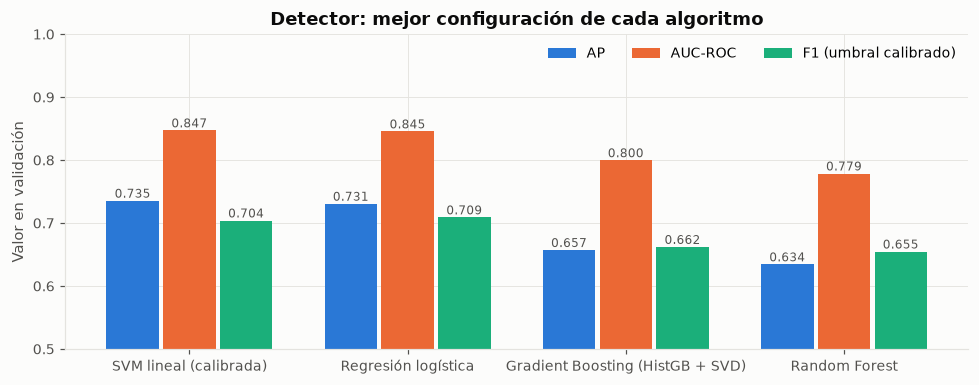

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
metricas_graf = [("val_ap", "AP"), ("val_roc_auc", "AUC-ROC"), ("val_f1_umbral", "F1 (umbral calibrado)")]
x = np.arange(len(mejores))
for k, (col, nombre) in enumerate(metricas_graf):
    b = ax.bar(x + (k - 1) * 0.26, mejores[col], width=0.24, color=E.SERIES[k], label=nombre)
    E.etiquetar_barras(ax, b, "{:.3f}")
ax.set_xticks(x, mejores["nombre"])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("Valor en validación")
ax.set_title("Detector: mejor configuración de cada algoritmo")
ax.legend(ncol=3, loc="upper right")
fig.tight_layout()
E.guardar(fig, "modelo_comparacion_detector")
plt.show()

## 4. Reentrenamiento de los cuatro algoritmos con su mejor configuración

Reproducción de la comparación: cada algoritmo se entrena con la partición de entrenamiento y se evalúa en
validación. Las curvas precisión–sensibilidad muestran el compromiso de cada uno.

In [8]:
rp = metricas["representacion"]
R = representacion(binario=rp["binario"], estilo=rp["estilo"]).fit(a_unidades(tr))
from scipy import sparse  # noqa: E402

bl_tr = [t.transform(a_unidades(tr)) for _, t in R.transformer_list]
bl_va = [t.transform(a_unidades(va)) for _, t in R.transformer_list]
curvas = {}
for _, fila in mejores.iterrows():
    peso = fila["peso_seguridad"]
    Xtr = sparse.hstack([bl_tr[0], bl_tr[1], bl_tr[2] * peso]).tocsr()
    Xva = sparse.hstack([bl_va[0], bl_va[1], bl_va[2] * peso]).tocsr()
    t0 = time.time()
    m = crear_clasificador(fila["algoritmo"], **json.loads(fila["hiperparametros"])).fit(Xtr, tr.vulnerable)
    p = m.predict_proba(Xva)[:, 1]
    curvas[fila["nombre"]] = p
    print(f"{fila['nombre']:32s} AP={average_precision_score(va.vulnerable, p):.3f} AUC={roc_auc_score(va.vulnerable, p):.3f} "
          f"F1@0.5={f1_score(va.vulnerable, p >= 0.5):.3f} ({time.time() - t0:.0f} s)")

SVM lineal (calibrada)           AP=0.735 AUC=0.847 F1@0.5=0.695 (3 s)


Regresión logística              AP=0.731 AUC=0.845 F1@0.5=0.707 (4 s)


Gradient Boosting (HistGB + SVD) AP=0.657 AUC=0.800 F1@0.5=0.640 (45 s)


Random Forest                    AP=0.634 AUC=0.779 F1@0.5=0.621 (2 s)


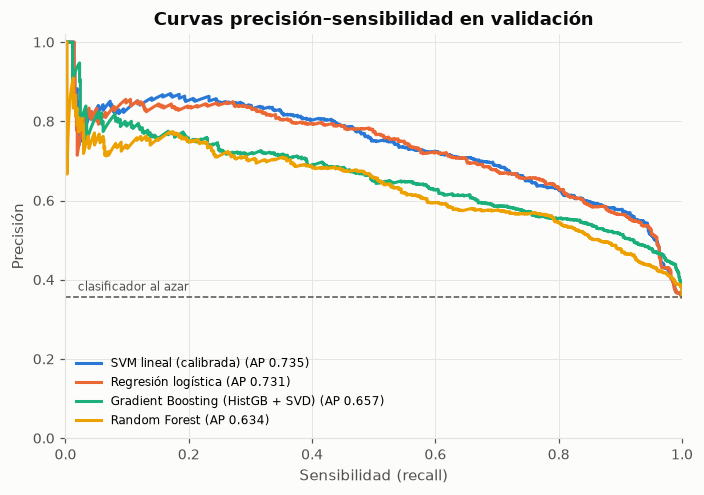

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for k, (nombre, p) in enumerate(curvas.items()):
    prec, rec, _ = precision_recall_curve(va.vulnerable, p)
    ax.plot(rec, prec, color=E.SERIES[k], linewidth=2, label=f"{nombre} (AP {average_precision_score(va.vulnerable, p):.3f})")
ax.axhline(va.vulnerable.mean(), color=E.TEXTO_2, linestyle="--", linewidth=1)
ax.annotate("clasificador al azar", (0.02, va.vulnerable.mean()), xytext=(0, 4), textcoords="offset points", fontsize=8, color=E.TEXTO_2)
ax.set_xlabel("Sensibilidad (recall)")
ax.set_ylabel("Precisión")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title("Curvas precisión–sensibilidad en validación")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
E.guardar(fig, "modelo_curvas_pr")
plt.show()

## 5. Comparación del categorizador multietiqueta (validación)

Se entrena con las unidades vulnerables de entrenamiento y se mide en las vulnerables de validación.
Criterio de selección: **F1 macro**, el promedio de F1 entre categorías, para que las categorías escasas
pesen lo mismo que la inyección.

In [10]:
t = comp_cat[["nombre", "val_f1_micro", "val_f1_macro", "val_f1_macro_umbral05", "val_exactitud_subconjunto", "segundos"]].round(3)
t.columns = ["Algoritmo", "F1 micro", "F1 macro (umbrales calibrados)", "F1 macro (umbral 0,5)", "Exactitud de subconjunto", "Segundos"]
t.sort_values("F1 macro (umbrales calibrados)", ascending=False).reset_index(drop=True)

,Algoritmo,F1 micro,F1 macro (umbrales calibrados),"F1 macro (umbral 0,5)",Exactitud de subconjunto,Segundos
0,Regresión logística,0.757,0.667,0.579,0.651,4.3
1,SVM lineal (calibrada),0.745,0.601,0.454,0.648,6.1
2,Random Forest,0.688,0.584,0.351,0.556,7.9
3,Gradient Boosting (HistGB + SVD),0.641,0.438,0.401,0.556,33.7


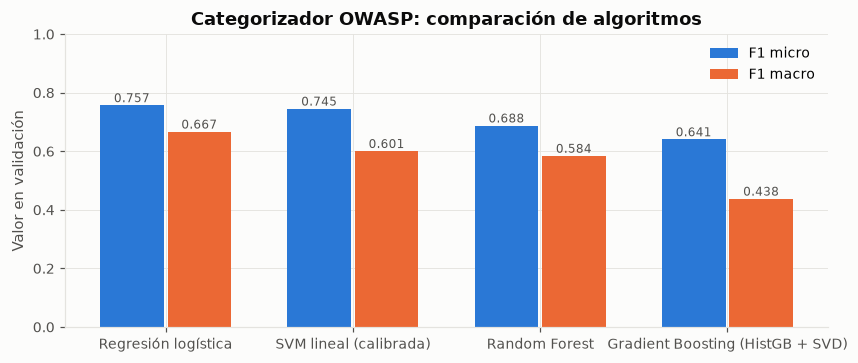

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
orden = comp_cat.sort_values("val_f1_macro", ascending=False)
x = np.arange(len(orden))
for k, (col, nombre) in enumerate((("val_f1_micro", "F1 micro"), ("val_f1_macro", "F1 macro"))):
    b = ax.bar(x + (k - 0.5) * 0.36, orden[col], width=0.34, color=E.SERIES[k], label=nombre)
    E.etiquetar_barras(ax, b, "{:.3f}")
ax.set_xticks(x, orden["nombre"])
ax.set_ylim(0, 1)
ax.set_ylabel("Valor en validación")
ax.set_title("Categorizador OWASP: comparación de algoritmos")
ax.legend(loc="upper right")
fig.tight_layout()
E.guardar(fig, "modelo_comparacion_categorias")
plt.show()

## 6. Selección del modelo y justificación

In [12]:
d, c = metricas["detector"], metricas["categorias"]
print(f"Detector seleccionado: {NOMBRES_ALGORITMO[d['algoritmo']]} {d['hiperparametros']} "
      f"(peso de las características de seguridad: {metricas['representacion']['peso_seguridad']})")
print(f"Categorizador seleccionado: {NOMBRES_ALGORITMO[c['algoritmo']]} {c['hiperparametros']}")
print(f"Categorías con clasificador: {len(c['evaluadas'])} | no evaluadas: {c['no_evaluadas']}")

Detector seleccionado: SVM lineal (calibrada) {'C': 1.0} (peso de las características de seguridad: 1.0)
Categorizador seleccionado: Regresión logística {'C': 8.0}
Categorías con clasificador: 18 | no evaluadas: {'API6:2023': 'datos insuficientes para entrenar (0 ejemplos; mínimo 15)', 'API9:2023': 'datos insuficientes para entrenar (1 ejemplos; mínimo 15)'}


La **regresión logística** obtiene la mayor precisión promedio en validación y, además:

- Es la más estable entre configuraciones y la que mejor aprovecha la representación dispersa de
  ≈ 120 000 variables. Random Forest y Gradient Boosting necesitan reducir la dimensión (χ² o SVD) y
  pierden información léxica fina.
- Produce **probabilidades calibradas**, necesarias para el umbral y para informar la confianza.
- Es **interpretable**: el peso de cada término y de cada característica de seguridad puede revisarse.
- Entrena en segundos y predice en milisegundos, lo que permite analizar proyectos completos en la CLI.

## 7. Umbral de decisión

Calculé dos umbrales:

- **Umbral de validación:** maximiza F1 en la partición de validación. Es apropiado para fragmentos
  parecidos a los de entrenamiento.
- **Umbral operativo:** el menor umbral cuya tasa de falsas alarmas en los proyectos limpios del conjunto
  de desarrollo es de 5 % o menos. Fija un "presupuesto de ruido" para el análisis de proyectos completos y
  maximiza la detección dentro de ese presupuesto. **Es el umbral que usa la herramienta.**

In [13]:
dv = metricas["desarrollo"]
pd.DataFrame({"Umbral de validación": dv["con_umbral_validacion"], "Umbral operativo": dv["con_umbral_operativo"]}).T[
    ["umbral", "sensibilidad", "falsas_alarmas", "ap", "auc"]].round(3)

,umbral,sensibilidad,falsas_alarmas,ap,auc
Umbral de validación,0.35,0.722,0.05,0.582,0.926
Umbral operativo,0.35,0.722,0.05,0.582,0.926


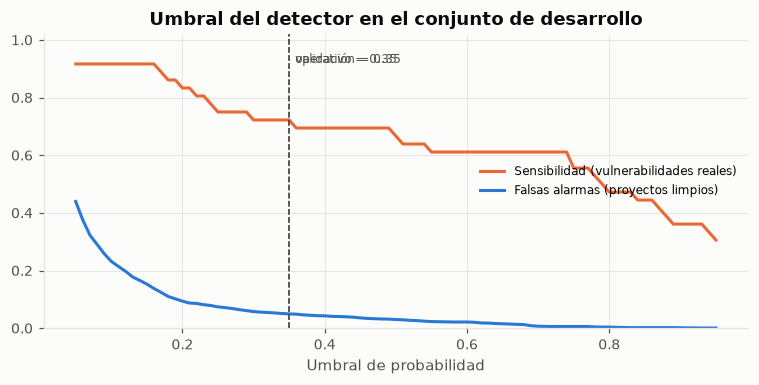

Umbrales por categoría (validación): {'A01:2025': 0.3, 'A02:2025': 0.2, 'A03:2025': 0.25, 'A04:2025': 0.33, 'A05:2025': 0.47, 'A06:2025': 0.62, 'A07:2025': 0.19, 'A08:2025': 0.73, 'A09:2025': 0.7, 'A10:2025': 0.52, 'API1:2023': 0.31, 'API2:2023': 0.49, 'API3:2023': 0.47, 'API4:2023': 0.18, 'API5:2023': 0.16, 'API7:2023': 0.41, 'API8:2023': 0.39, 'API10:2023': 0.16}


In [14]:
import desarrollo  # noqa: E402

modelo = ModeloVulnminer.cargar(BASE / "vulnminer" / "modelos" / "vulnminer.joblib")
dev_pos, dev_neg = desarrollo.cargar()
p_pos, p_neg = modelo.probabilidad(dev_pos), modelo.probabilidad(dev_neg)
umbrales = np.arange(0.05, 0.96, 0.01)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(umbrales, [(p_pos >= u).mean() for u in umbrales], color=E.NARANJA, linewidth=2, label="Sensibilidad (vulnerabilidades reales)")
ax.plot(umbrales, [(p_neg >= u).mean() for u in umbrales], color=E.AZUL, linewidth=2, label="Falsas alarmas (proyectos limpios)")
for u, nombre in ((dv["umbral_validacion"], "validación"), (modelo.umbral, "operativo")):
    ax.axvline(u, color=E.TEXTO_2, linestyle="--", linewidth=1)
    ax.annotate(f"{nombre} = {u:.2f}", (u, 0.92), xytext=(4, 0), textcoords="offset points", fontsize=8, color=E.TEXTO_2)
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylim(0, 1.02)
ax.set_title("Umbral del detector en el conjunto de desarrollo")
ax.legend(loc="center right", fontsize=8)
fig.tight_layout()
E.guardar(fig, "modelo_umbral")
plt.show()
print("Umbrales por categoría (validación):", c["umbrales"])

## 8. Modelo final serializado

El modelo final se reentrena con **entrenamiento + validación** usando la configuración y los umbrales
elegidos, y se guarda con `joblib` junto con el pipeline de representación en
`vulnminer/modelos/vulnminer.joblib`. La CLI lo carga y **no vuelve a entrenar** en cada ejecución.

Después de la evaluación (notebook 05, secciones 6 y 7) se añadió al mismo archivo una **etapa de
combinación** ajustada con el conjunto de desarrollo (`scripts/combinar.py`): en el código de servidor,
la decisión considera también la cantidad de evidencia estática. El modelo base no se modifica.

In [15]:
ruta = BASE / "vulnminer" / "modelos" / "vulnminer.joblib"
print(f"Archivo: {ruta.relative_to(BASE)} ({ruta.stat().st_size / 1e6:.1f} MB)")
print("Componentes:", type(modelo.representacion).__name__, "|", type(modelo.detector).__name__, "|",
      type(modelo.categorizador).__name__, "|", type(modelo.clasificador_cwe).__name__)
print("Clases de CWE:", len(modelo.clasificador_cwe.classes_))
print(f"Umbral del modelo base: {modelo.umbral} | combinación (código de servidor): p >= {modelo.umbral_base_codigo} "
      f"o probabilidad combinada >= {modelo.umbral_combinado}")

Archivo: vulnminer/modelos/vulnminer.joblib (41.2 MB)
Componentes: FeatureUnion | CalibratedClassifierCV | OneVsRestClassifier | LogisticRegression
Clases de CWE: 51
Umbral del modelo base: 0.35 | combinación (código de servidor): p >= 0.45 o probabilidad combinada >= 0.88


### Predicción con el pipeline serializado

In [16]:
from vulnminer.segmentacion import segmentar  # noqa: E402

nuevo = '''@router.get("/invoices/{invoice_id}")
def read_invoice(invoice_id: int, db: Session = Depends(get_db), user=Depends(get_current_user)):
    return db.query(Invoice).filter(Invoice.id == invoice_id).first()

@router.get("/invoices/{invoice_id}/secure")
def read_invoice_secure(invoice_id: int, db: Session = Depends(get_db), user=Depends(get_current_user)):
    return db.query(Invoice).filter(Invoice.id == invoice_id, Invoice.owner_id == user.id).first()
'''
for u, p in zip(segmentar("invoices.py", nuevo), modelo.predecir(segmentar("invoices.py", nuevo))):
    print(f"{u.nombre:22s} P(vulnerable)={p['probabilidad']:.3f} -> {'VULNERABLE' if p['vulnerable'] else 'no vulnerable'} "
          f"| categorías: {[c for c, _ in p['owasp2025'] + p['api2023']]}")

read_invoice           P(vulnerable)=0.998 -> VULNERABLE | categorías: ['A01:2025', 'API1:2023', 'API5:2023']
read_invoice_secure    P(vulnerable)=0.389 -> no vulnerable | categorías: []
